# Canteen Food Demand Forecasting with a Stacking Ensemble (Improved Method)

This notebook is a modified copy of `canteen_methodology.ipynb`. It uses the same models (Random Forest, XGBoost, SVR, LSTM and two stacking ensembles) with the same settings, but prepares the data so that the models never see information from the test period or from the value they are predicting. It also adds descriptive statistics and evaluation metrics, and reduces the training time of the stacking ensembles. Changed lines in the code are marked `# CHANGED:`.

Changes from `canteen_methodology.ipynb`:
1. `Net_price` is no longer used as an input (Section 0).
2. Descriptive statistics and histograms of the numeric variables are added (Section 3).
3. The data is split by date instead of at random: the first 80 % of days for training and the last 20 % for testing (Section 4).
4. Missing lag values are filled with training-set means after the split, instead of full-data means before it (Sections 2 and 4).
5. MSE, RMSE and SMAPE are added to the metrics (Section 5).
6. The LSTM is tested on the same days as the other models and trains only on days with a full 10-day history (Section 7).
7. The stacking meta-learner is tuned with `RidgeCV` instead of a grid search that retrains the whole stack (Sections 8 and 9).
8. A new section compares the training time and accuracy of both tuning methods (Section 11).

| Section | Content |
|---|---|
| 0 | Setup: dataset location, libraries, configuration |
| 1 | Data loading and integrity checks |
| 2 | Feature engineering: date features and lagged sales |
| 3 | Data analysis and descriptive statistics |
| 4 | One-hot encoding, train/test split by date, imputation, scaling |
| 5 | Evaluation metrics |
| 6 | Random Forest, XGBoost and SVR with grid search |
| 7 | LSTM |
| 8 | Stacking 1: RF + XGBoost + SVR → Ridge |
| 9 | Stacking 2: RF + XGBoost + SVR + LSTM → Ridge |
| 10 | Results and plots |
| 11 | Stacking training time vs accuracy |

## 0. Setup
This section locates the dataset, imports the libraries and sets the configuration used throughout the notebook.

In [1]:
# Locate the dataset. On Google Colab the GitHub repository is cloned first;
# when run locally, the notebook already sits next to the dataset in the repository folder.
import os, sys
GITHUB_USER = "yklee7285"                     # GitHub account that hosts the public repository
REPO        = "food-demand-forecasting-fyp"
DATA_PATH   = "datasets/canteen_sales_2025_2026.xlsx"

if "google.colab" in sys.modules and not os.path.exists(DATA_PATH):
    if not os.path.isdir(REPO):
        !git clone -q https://github.com/{GITHUB_USER}/{REPO}.git
    %cd {REPO}

In [2]:
# Standard library; hide warnings and TensorFlow start-up logs
import time, random, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# Data handling, plotting and statistical tests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# scikit-learn: splitting, tuning, scaling, models and metrics
from sklearn.model_selection import GridSearchCV   # CHANGED: train_test_split removed because the split is now by date
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge, RidgeCV   # CHANGED: RidgeCV added for the stacking meta-learner
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score   # CHANGED: mean_squared_error added for MSE and RMSE
from xgboost import XGBRegressor

# TensorFlow / Keras for the LSTM
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
tf.get_logger().setLevel("ERROR")
sns.set_style("whitegrid")

# ---------------- Configuration ----------------
RANDOM_STATE      = 42        # seed for the tree models and the LSTM (CHANGED: no longer used for the split)
TEST_SIZE         = 0.20      # share of days held out for testing
CV_FOLDS          = 5         # folds for grid-search cross-validation and stacking
SCORING           = "neg_mean_absolute_error"   # grid search keeps the parameters with the lowest MAE
SEQ_LEN           = 10        # LSTM input length: the 10 preceding operating days
WEEK_DAYS         = 6         # one operating week (Monday-Saturday) for the weekly lag
USE_NET_PRICE     = False     # CHANGED: was True. Net_price is quantity x price, so it contains the target and is not known in advance
LSTM_SCALE_TARGET = True      # LSTM learns a 0-1 scaled target; predictions are converted back to meals
SVR_TARGET_SD     = 9.63      # SVR learns the target rescaled to this standard deviation; predictions are converted back to meals
RIDGE_GRID        = {"alpha": [0.01, 0.1, 1, 10, 100]}   # alpha values tested for the Ridge meta-learner
TARGET            = "Quantity_sold"                     # column being forecast

def set_seeds(seed=RANDOM_STATE):
    # Fix the Python, NumPy and TensorFlow random generators so results are repeatable
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)
set_seeds()

## 1. Data loading and checks
This loads the dataset, sorts it by date and prints basic integrity checks. Each printed value should match its "expect" value.

In [3]:
df = pd.read_excel(DATA_PATH)
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df = df.sort_values("Timestamp").reset_index(drop=True)      # lag features and LSTM windows rely on chronological order

# Integrity checks: each printed value should match its "expect" value
print("Rows:", len(df), "| Range:", df.Timestamp.min().date(), "to", df.Timestamp.max().date())
print("Duplicates (expect 0):", df.Timestamp.duplicated().sum(), "| Missing values (expect 0):", df.isna().sum().sum())
print("Sundays (expect 0):", (df.Timestamp.dt.dayofweek == 6).sum())
print("Net_price mismatches (expect 0):", ((df[TARGET] * df.Price_per_meal - df.Net_price).abs() > 0.01).sum())
print("Mean quantity (expect ~6,440):", round(df[TARGET].mean(), 1))
display(df.head())

Rows: 626 | Range: 2025-01-01 to 2026-12-31
Duplicates (expect 0): 0 | Missing values (expect 0): 0
Sundays (expect 0): 0
Net_price mismatches (expect 0): 0
Mean quantity (expect ~6,440): 6422.6


,Timestamp,Day_of_Week,Weekend_Status,Academic_Period,Quantity_sold,Price_per_meal,Net_price
0,2025-01-01,Wednesday,Weekday,Teaching,7728,18.43,142427.04
1,2025-01-02,Thursday,Weekday,Teaching,6916,15.07,104224.12
2,2025-01-03,Friday,Weekday,Teaching,7997,8.56,68454.32
3,2025-01-04,Saturday,Weekend,Teaching,4340,17.79,77208.60
4,2025-01-06,Monday,Weekday,Teaching,6366,10.22,65060.52


## 2. Feature engineering
This adds model inputs derived from the date and from past sales:
* `Month`: month name.
* `Quantity_last_day`: meals sold on the previous operating day (Saturday's sales for a Monday).
* `Quantity_last_two_days`: total meals sold over the previous 2 operating days.
* `Quantity_last_week`: total meals sold over the previous 6 operating days (one Monday–Saturday week).

`Week_of_Month` is created only for the check in Section 3 and is not a model input. The first rows have no sales history for the lags. Those gaps are filled in Section 4, after the split, using training-set means.

In [4]:
df["Month"]         = df.Timestamp.dt.month_name()
df["Week_of_Month"] = (df.Timestamp.dt.day - 1) // 7 + 1           # 1-5; used only for the check in Section 3

# Lagged sales: shifting by one row first ensures a day's own sales never enter its lags
past = df[TARGET].shift(1)                                          # previous operating day
df["Quantity_last_day"]      = past
df["Quantity_last_two_days"] = past.rolling(2).sum()
df["Quantity_last_week"]     = past.rolling(WEEK_DAYS).sum()

# The first rows have no history yet; they are filled in Section 4
LAG_COLS = ["Quantity_last_day", "Quantity_last_two_days", "Quantity_last_week"]
print("Missing lag values (filled in Section 4):", df[LAG_COLS].isna().sum().to_dict())
# CHANGED: missing values are no longer filled here, because full-data means include test-period values
display(df[["Timestamp", "Day_of_Week", TARGET] + LAG_COLS].head(8))

Missing lag values (filled in Section 4): {'Quantity_last_day': 1, 'Quantity_last_two_days': 2, 'Quantity_last_week': 6}


,Timestamp,Day_of_Week,Quantity_sold,Quantity_last_day,Quantity_last_two_days,Quantity_last_week
0,2025-01-01,Wednesday,7728,NaN,NaN,NaN
1,2025-01-02,Thursday,6916,7728.0,NaN,NaN
2,2025-01-03,Friday,7997,6916.0,14644.0,NaN
3,2025-01-04,Saturday,4340,7997.0,14913.0,NaN
4,2025-01-06,Monday,6366,4340.0,12337.0,NaN
5,2025-01-07,Tuesday,6758,6366.0,10706.0,NaN
6,2025-01-08,Wednesday,7621,6758.0,13124.0,40105.0
7,2025-01-09,Thursday,7353,7621.0,14379.0,39998.0


## 3. Data analysis
This summarises the numeric variables with descriptive statistics and histograms, plots how meals sold vary with the main inputs, then tests whether week of the month has any effect on sales. The test is a one-way ANOVA: p > 0.05 means no meaningful effect, so week of the month is not used as an input.

### Descriptive statistics
Count, mean, standard deviation, range, skewness and kurtosis of each numeric variable, followed by their histograms. Skewness measures asymmetry (0 means symmetric) and kurtosis measures how heavy the tails are (0 is the same as a normal distribution). The missing counts are the lag values at the start of the series.

,count,mean,std,min,25%,50%,75%,max,missing,skewness,kurtosis
Quantity_sold,626.0,6422.618,1772.441,855.00,4708.500,7159.00,7744.250,9302.00,0,-0.786,-0.620
Price_per_meal,626.0,12.402,4.394,5.01,8.605,12.17,16.278,19.99,0,0.073,-1.232
Net_price,626.0,79851.121,36903.015,7549.65,51018.220,74055.55,106487.745,182148.88,0,0.377,-0.823
Quantity_last_day,625.0,6421.339,1773.572,855.00,4693.000,7158.00,7745.000,9302.00,1,-0.784,-0.625
Quantity_last_two_days,624.0,12838.330,2808.648,4487.00,10898.750,13863.00,15170.250,18051.00,2,-0.639,-0.526
Quantity_last_week,620.0,38498.198,6249.120,20650.00,39155.750,40974.00,42056.500,45699.00,6,-1.655,1.294


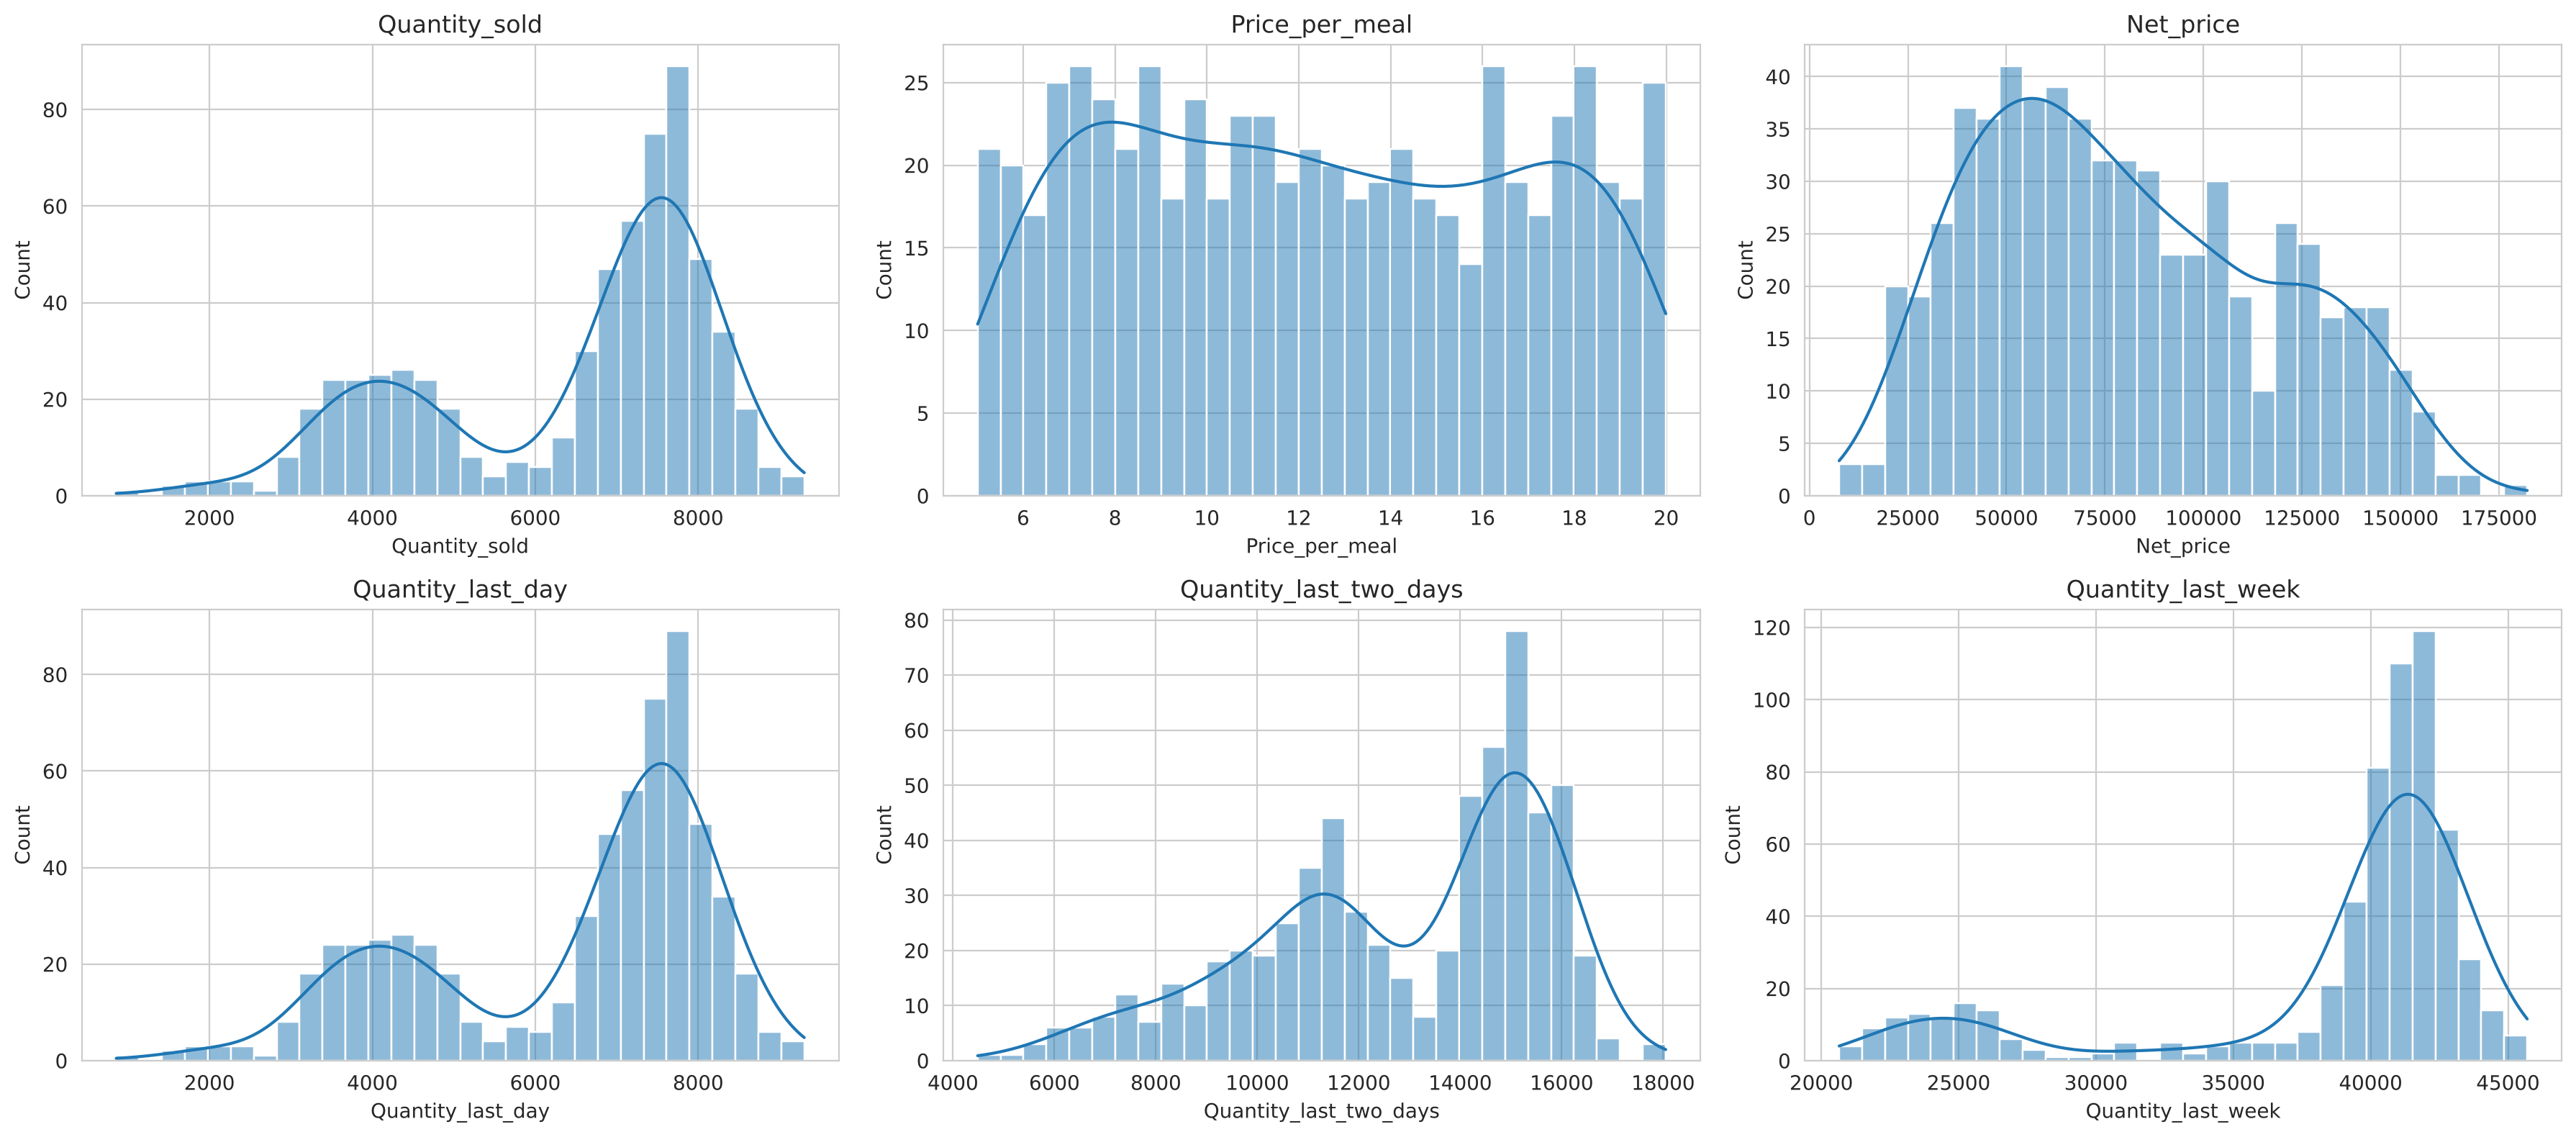

In [5]:
# CHANGED: new cell for descriptive statistics and histograms of the numeric variables
NUMERIC = [TARGET, "Price_per_meal", "Net_price"] + LAG_COLS
desc = df[NUMERIC].describe().T                      # count, mean, std, min, quartiles, max
desc["missing"]  = df[NUMERIC].isna().sum()
desc["skewness"] = df[NUMERIC].skew()
desc["kurtosis"] = df[NUMERIC].kurt()                # excess kurtosis, 0 for a normal distribution
display(desc.round(3))

# Histogram of each numeric variable
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for a, col in zip(axes.ravel(), NUMERIC):
    sns.histplot(df[col].dropna(), bins=30, kde=True, ax=a).set_title(col)
plt.tight_layout(); plt.show()

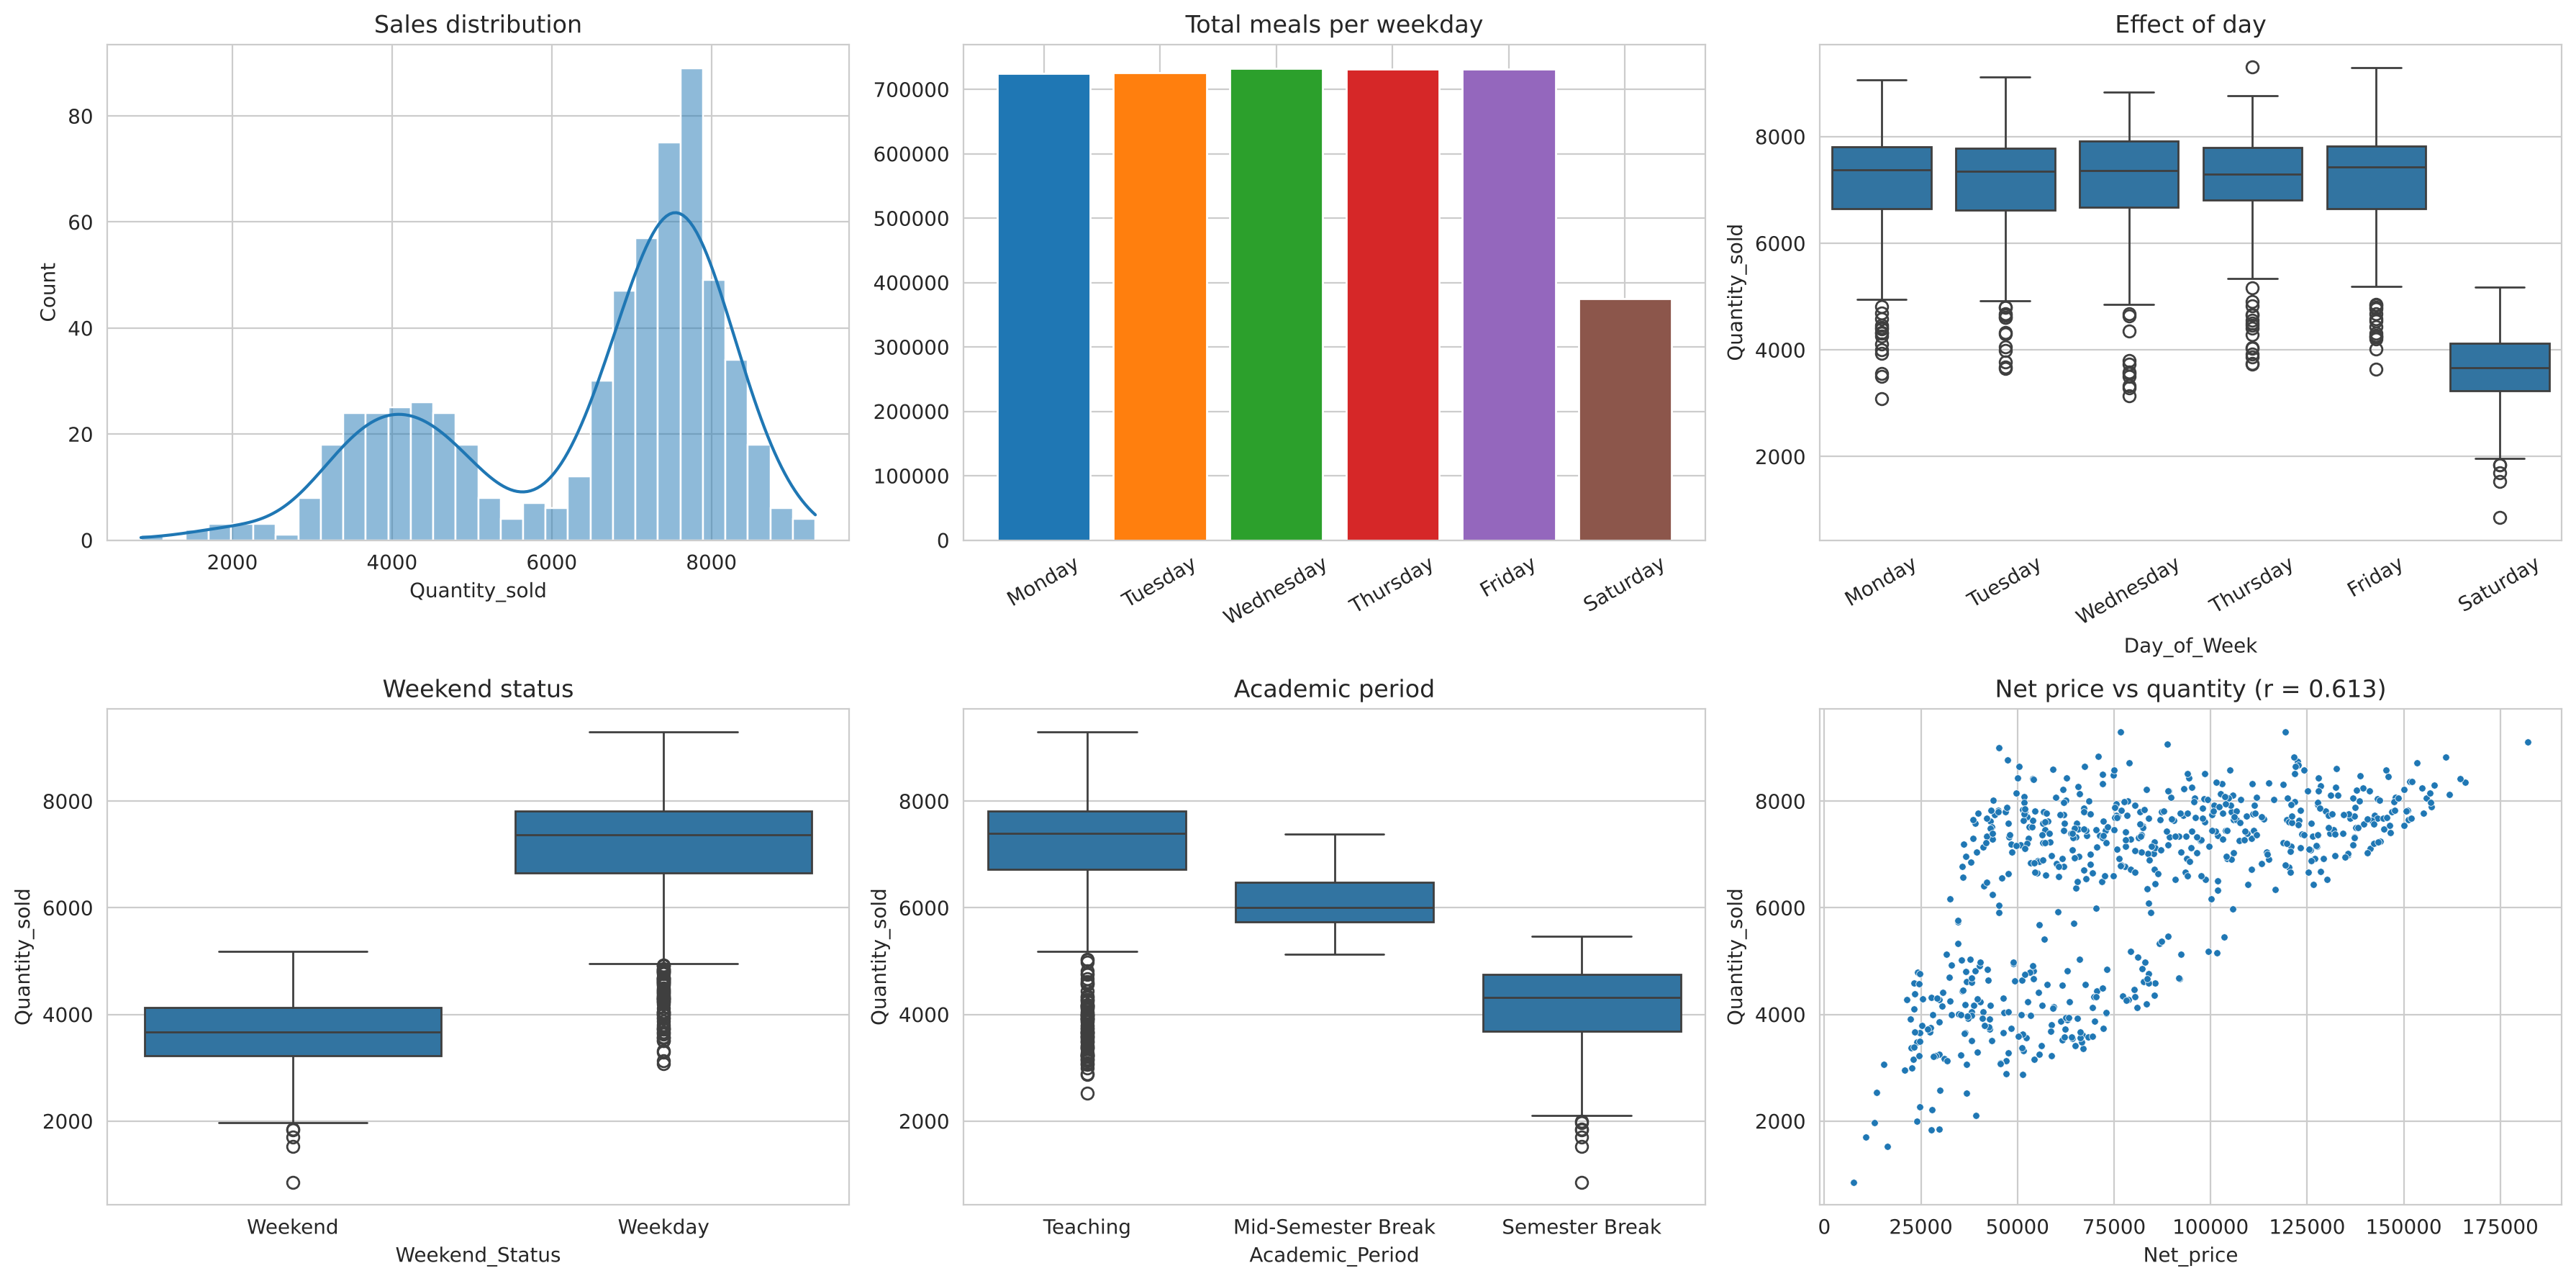

Week-of-month ANOVA: F = 0.387, p = 0.818 -> excluded (no meaningful effect)


In [6]:
DAYS    = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]
PERIODS = ["Teaching", "Mid-Semester Break", "Semester Break"]
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
# Distribution of daily meals sold
sns.histplot(df[TARGET], bins=30, kde=True, ax=ax[0, 0]).set_title("Sales distribution")
# Total meals sold on each weekday
ax[0, 1].bar(DAYS, df.groupby("Day_of_Week")[TARGET].sum().reindex(DAYS), color=sns.color_palette("tab10", 6))
ax[0, 1].set_title("Total meals per weekday"); ax[0, 1].tick_params(axis="x", rotation=30)
# Daily meals by weekday, weekend status and academic period
sns.boxplot(data=df, x="Day_of_Week", y=TARGET, order=DAYS, ax=ax[0, 2]).set_title("Effect of day")
ax[0, 2].tick_params(axis="x", rotation=30)
sns.boxplot(data=df, x="Weekend_Status", y=TARGET, order=["Weekend", "Weekday"], ax=ax[1, 0]).set_title("Weekend status")
sns.boxplot(data=df, x="Academic_Period", y=TARGET, order=PERIODS, ax=ax[1, 1]).set_title("Academic period")
# Net price against quantity, with their correlation in the title
sns.scatterplot(data=df, x="Net_price", y=TARGET, s=12, ax=ax[1, 2]).set_title(
    f"Net price vs quantity (r = {df[['Net_price', TARGET]].corr().iloc[0, 1]:.3f})")
plt.tight_layout(); plt.show()

# One-way ANOVA: does mean sales differ between weeks of the month?
f, p = stats.f_oneway(*[g[TARGET].values for _, g in df.groupby("Week_of_Month")])
print(f"Week-of-month ANOVA: F = {f:.3f}, p = {p:.3f} -> {'excluded (no meaningful effect)' if p > 0.05 else 'significant'}")

## 4. Encoding, split, imputation and scaling
1. Categorical inputs are one-hot encoded (one 0/1 column per category).
2. Days are split by date: the first 80 % of days form the training set and the last 20 % the test set, so every model is trained on earlier days and tested on later ones. The split is made on row numbers so the LSTM windows use the same training and test days.
3. Missing lag values are filled with the training-set mean of each lag column.
4. Inputs are scaled to 0–1 with a scaler fitted on the training rows only, so no test information enters training. The target stays in meals.

In [7]:
CAT_COLS = ["Day_of_Week", "Month", "Weekend_Status", "Academic_Period"]
NUM_COLS = ["Price_per_meal"] + (["Net_price"] if USE_NET_PRICE else []) + LAG_COLS

X = pd.get_dummies(df[CAT_COLS + NUM_COLS], columns=CAT_COLS, dtype=float)    # one-hot encode the categorical columns
y = df[TARGET].to_numpy(dtype=float)

# CHANGED: split by date instead of at random, so no training day comes after a test day
n_test = int(np.ceil(len(df) * TEST_SIZE))                    # 126 test days, the same number as the random split
idx_tr, idx_te = np.arange(len(df) - n_test), np.arange(len(df) - n_test, len(df))
print("Train:", df.Timestamp.iloc[idx_tr[0]].date(), "to", df.Timestamp.iloc[idx_tr[-1]].date(),
      "| Test:", df.Timestamp.iloc[idx_te[0]].date(), "to", df.Timestamp.iloc[idx_te[-1]].date())

# CHANGED: missing lag values filled with training-set means (previously full-data means before the split)
X = X.fillna(X.iloc[idx_tr].mean())

# Fit the scaler on training predictors only, then apply it to every row
scaler = MinMaxScaler().fit(X.iloc[idx_tr])
X_all  = scaler.transform(X)
X_tr, X_te, y_tr, y_te = X_all[idx_tr], X_all[idx_te], y[idx_tr], y[idx_te]
print(f"{X.shape[1]} inputs | train {X_tr.shape} | test {X_te.shape}")
print(list(X.columns))

Train: 2025-01-01 to 2026-08-06 | Test: 2026-08-07 to 2026-12-31
27 inputs | train (500, 27) | test (126, 27)
['Price_per_meal', 'Quantity_last_day', 'Quantity_last_two_days', 'Quantity_last_week', 'Day_of_Week_Friday', 'Day_of_Week_Monday', 'Day_of_Week_Saturday', 'Day_of_Week_Thursday', 'Day_of_Week_Tuesday', 'Day_of_Week_Wednesday', 'Month_April', 'Month_August', 'Month_December', 'Month_February', 'Month_January', 'Month_July', 'Month_June', 'Month_March', 'Month_May', 'Month_November', 'Month_October', 'Month_September', 'Weekend_Status_Weekday', 'Weekend_Status_Weekend', 'Academic_Period_Mid-Semester Break', 'Academic_Period_Semester Break', 'Academic_Period_Teaching']


## 5. Evaluation metrics
$MAE=\frac1n\sum|y-\hat y|$ · $MSE=\frac1n\sum(y-\hat y)^2$ · $RMSE=\sqrt{MSE}$ · $MAPE=\frac{100}{n}\sum|\frac{y-\hat y}{y}|$ · $SMAPE=\frac{100}{n}\sum\frac{2|y-\hat y|}{|y|+|\hat y|}$ · $Accuracy=100-MAPE$ · $R^2=1-\frac{\sum(y-\hat y)^2}{\sum(y-\bar y)^2}$

`evaluate` turns one model's test predictions into a row of the results table. `results`, `preds` and `truth` collect every model's output for Section 10.

In [8]:
def evaluate(name, y_true, y_pred, secs):
    # One results-table row: error metrics (in meals / %), R2, training time and test-set size
    mape  = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    smape = np.mean(2 * np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred))) * 100   # CHANGED: SMAPE added
    mse   = mean_squared_error(y_true, y_pred)                                                # CHANGED: MSE added
    return {"Model": name, "MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse),                                                               # CHANGED: RMSE added
            "MAPE (%)": mape, "SMAPE (%)": smape,
            "Accuracy (%)": 100 - mape, "R2": r2_score(y_true, y_pred), "Training time (s)": secs,
            "Test rows": len(y_true)}
results, preds, truth = [], {}, {}      # metric rows, test predictions and matching actual values per model

## 6. Individual models: Random Forest, XGBoost, SVR
Each model is tuned by 5-fold grid search on the training set (lowest MAE wins), refitted on all training rows, and evaluated on the test set. The training time covers both the search and the refit. SVR is wrapped so that it learns the target rescaled to a standard deviation of `SVR_TARGET_SD`; its predictions are converted back to meals.

In [9]:
svr_k = y_tr.std() / SVR_TARGET_SD     # factor that rescales the training target to SVR_TARGET_SD

GRIDS = {   # each model with its candidate hyperparameter values
    "RF":      (RandomForestRegressor(random_state=RANDOM_STATE),
                {"n_estimators": [50, 100], "max_depth": [5, 10, 20, None], "min_samples_split": [2, 5]}),
    "XGBoost": (XGBRegressor(random_state=RANDOM_STATE, n_jobs=1),
                {"n_estimators": [50, 100], "learning_rate": [0.05, 0.1, 0.2], "max_depth": [3, 5, 7]}),
    # SVR (default RBF kernel and gamma) learns the target divided by svr_k; predictions are multiplied back to meals
    "SVR":     (TransformedTargetRegressor(SVR(), func=lambda v: v / svr_k, inverse_func=lambda v: v * svr_k),
                {"regressor__C": [0.1, 1], "regressor__epsilon": [0.1, 0.2]}),
}
best = {}   # tuned model per name, reused by the stacking ensembles
for name, (est, grid) in GRIDS.items():
    # Grid search with 5-fold CV, then refit of the best setting on all training rows (timed together)
    t0 = time.time()
    gs = GridSearchCV(est, grid, cv=CV_FOLDS, scoring=SCORING, n_jobs=-1).fit(X_tr, y_tr)
    secs = time.time() - t0
    best[name], preds[name], truth[name] = gs.best_estimator_, gs.predict(X_te), y_te
    results.append(evaluate(name, y_te, preds[name], secs))
    print(f"{name:8s} {gs.best_params_}  ({secs:.1f}s)")

RF       {'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 100}  (6.9s)


XGBoost  {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}  (2.1s)
SVR      {'regressor__C': 1, 'regressor__epsilon': 0.1}  (0.2s)


## 7. LSTM
Each sample is a window of the **10 preceding operating days** (all scaled inputs), and the label is the meals sold on the following day. The windows use the same training and test days as the other models. The first 10 training days have no full 10-day history, so they are left out of the LSTM's training set. The test windows are passed as validation data, which only reports a score during training and does not change the model.

In [10]:
def build_lstm(n_features):
    # Two stacked LSTM layers (50 units each) with 20 % dropout after each, then one output neuron
    model = Sequential([Input(shape=(SEQ_LEN, n_features)),
                        LSTM(50, return_sequences=True), Dropout(0.2),
                        LSTM(50, return_sequences=False), Dropout(0.2),
                        Dense(1)])
    model.compile(optimizer="adam", loss="mse")           # Adam with its default learning rate, mean squared error loss
    return model

class LSTMRegressor:
    # Wraps the Keras LSTM with optional 0-1 target scaling; predictions always come back in meals.
    def __init__(self, n_features, scale_target=LSTM_SCALE_TARGET):
        self.n_features, self.scale_target = n_features, scale_target
    def fit(self, W, y, validation_data=None):
        set_seeds()                                        # every LSTM starts from the same random state
        self.ys = MinMaxScaler().fit(y.reshape(-1, 1)) if self.scale_target else None
        f = (lambda v: self.ys.transform(v.reshape(-1, 1)).ravel()) if self.scale_target else (lambda v: v)
        val = None if validation_data is None else (validation_data[0], f(validation_data[1]))
        self.model = build_lstm(self.n_features)
        self.model.fit(W, f(y), epochs=20, batch_size=32, validation_data=val, verbose=0)
        return self
    def predict(self, W):
        p = self.model.predict(W, verbose=0)
        return (self.ys.inverse_transform(p) if self.scale_target else p).ravel()

def make_windows(days):
    # Window for day t = rows t-10 ... t-1. Rows before day 0 are padded by repeating day 0
    # (only Stacking 2 needs that, because it must predict every row).
    return np.stack([X_all[np.clip(np.arange(t - SEQ_LEN, t), 0, None)] for t in days])

# CHANGED: windows are built from the date split, so the LSTM is tested on the same 126 days as the other models.
# Previously the 616 complete windows were split separately at random, giving 124 test days that were mostly different days.
# Only training days with 10 days of history are used, so no padded windows are needed.
lstm_tr = idx_tr[idx_tr >= SEQ_LEN]
W_tr, W_te = make_windows(lstm_tr), make_windows(idx_te)
yw_tr, yw_te = y[lstm_tr], y_te

# Train (timed), predict the test windows and record the metrics
t0 = time.time()
lstm = LSTMRegressor(W_tr.shape[2]).fit(W_tr, yw_tr, validation_data=(W_te, yw_te))   # CHANGED: number of features taken from W_tr
secs = time.time() - t0
preds["LSTM"], truth["LSTM"] = lstm.predict(W_te), yw_te
results.append(evaluate("LSTM", yw_te, preds["LSTM"], secs))
print(f"LSTM trained in {secs:.1f}s")

LSTM trained in 6.7s


## 8. Stacking 1: RF + XGBoost + SVR → Ridge
The tuned RF, XGBoost and SVR models are combined with scikit-learn's `StackingRegressor`:
1. 5-fold cross-validation produces an out-of-fold prediction from each base model for every training row.
2. A Ridge regression learns how to weight those predictions. It sees only the predictions, not the original inputs.
3. The base models are refitted on all training rows.

Ridge's regularisation strength (`alpha`) is chosen by `RidgeCV` from the same candidate values, using MAE and leave-one-out cross-validation on the out-of-fold predictions. Since `alpha` only affects the Ridge step, the base models do not need to be retrained to compare `alpha` values, so each base model is trained 6 times (5 folds and a final fit) instead of once for every `alpha` value and fold. Section 11 measures the time saved.

In [11]:
t0 = time.time()
# Stack of the tuned base models with a Ridge meta-learner trained on 5-fold out-of-fold predictions.
# CHANGED: alpha is chosen by RidgeCV inside the stack instead of by a GridSearchCV around the whole stack.
# Alpha only affects the Ridge step, but the grid search retrained every base model for each of the
# 5 alpha values and 5 folds. RidgeCV tests the same alpha values with MAE on the out-of-fold predictions
# the stack already has, so the base models are only trained once. The model and settings are the same.
s1 = StackingRegressor(estimators=[("rf", best["RF"]), ("xgb", best["XGBoost"]), ("svr", best["SVR"])],
                       final_estimator=RidgeCV(alphas=RIDGE_GRID["alpha"], scoring=SCORING),
                       cv=CV_FOLDS, passthrough=False, n_jobs=-1).fit(X_tr, y_tr)
secs = time.time() - t0
preds["Stacking 1"], truth["Stacking 1"] = s1.predict(X_te), y_te
results.append(evaluate("Stacking 1 (RF, XGBoost, SVR)", y_te, preds["Stacking 1"], secs))
print(f"Stacking 1: alpha = {s1.final_estimator_.alpha_} | Ridge weights [RF, XGB, SVR] = {np.round(s1.final_estimator_.coef_, 3)} ({secs:.1f}s)")   # CHANGED: alpha read from RidgeCV

Stacking 1: alpha = 0.01 | Ridge weights [RF, XGB, SVR] = [ 1.064 -0.224  0.187] (0.9s)


## 9. Stacking 2: RF + XGBoost + SVR + LSTM → Ridge
This uses the same stacking procedure as Stacking 1 (including `RidgeCV` for the meta-learner), with the LSTM added as a fourth base model.
* Each row's input is `[day features | flattened 10-day window]`. Column selectors give RF, XGBoost and SVR the day features only, and the LSTM the window only.
* With `STACK2_LSTM_MODE = "prefit"`, the LSTM is trained once on the training rows (included in the training time) and reused inside every fold. `"refit"` trains a new LSTM in every fold instead, which takes about 15–20 minutes.
* The prefit LSTM has already seen the training rows, so the cell after the model compares its accuracy on those rows with its accuracy on unseen test rows.

In [12]:
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin
from sklearn.pipeline import Pipeline
from joblib import parallel_backend

STACK2_LSTM_MODE = "prefit"   # "prefit" = LSTM trained once and reused in every fold; "refit" = new LSTM trained in every fold
PREFIT_LSTM = {}              # the once-trained LSTM, looked up by key so sklearn's clone() never copies a Keras model

class ColumnSlice(TransformerMixin, BaseEstimator):
    # Keeps columns [start, stop) of the combined input.
    def __init__(self, start=0, stop=None):
        self.start, self.stop = start, stop
    def fit(self, Z, y=None):
        return self
    def transform(self, Z):
        return Z[:, self.start:self.stop]

class WindowLSTM(RegressorMixin, BaseEstimator):
    # LSTM base model for StackingRegressor; input = flattened 10-day windows.
    # With prefit_key, fit() only attaches the once-trained model; otherwise it trains a new LSTM.
    def __init__(self, n_features=1, prefit_key=None):
        self.n_features, self.prefit_key = n_features, prefit_key
    def _windows(self, Z):
        return Z.reshape(-1, SEQ_LEN, self.n_features)      # flat rows back to (samples, 10 days, features)
    def fit(self, Z, y):
        self.model_ = (PREFIT_LSTM[self.prefit_key] if self.prefit_key
                       else LSTMRegressor(self.n_features).fit(self._windows(Z), y))
        return self
    def predict(self, Z):
        return self.model_.predict(self._windows(Z))

# Combined input: the day's own features followed by its flattened 10-day window
p     = X_all.shape[1]
W_all = make_windows(np.arange(len(y)))                       # every row gets a window (first 10 padded)
Z_all = np.hstack([X_all, W_all.reshape(len(y), -1)])         # [day features | flattened window]
Z_tr, Z_te = Z_all[idx_tr], Z_all[idx_te]
on_day = lambda est: Pipeline([("day_features", ColumnSlice(0, p)), ("model", clone(est))])   # base model on day features only

t0 = time.time()
if STACK2_LSTM_MODE == "prefit":
    PREFIT_LSTM["stack2"] = LSTMRegressor(p).fit(W_all[idx_tr], y_tr)      # the single LSTM training
# LSTM base model on the window columns only
lstm_base = Pipeline([("window", ColumnSlice(p, None)),
                      ("model", WindowLSTM(p, "stack2" if STACK2_LSTM_MODE == "prefit" else None))])

# Same stacking set-up as Stacking 1, with the LSTM as a fourth base model.
# CHANGED: RidgeCV meta-learner instead of a GridSearchCV around the whole stack (see Section 8)
s2 = StackingRegressor(
    estimators=[("rf", on_day(best["RF"])), ("xgb", on_day(best["XGBoost"])), ("svr", on_day(best["SVR"])), ("lstm", lstm_base)],
    final_estimator=RidgeCV(alphas=RIDGE_GRID["alpha"], scoring=SCORING),
    cv=CV_FOLDS, passthrough=False, n_jobs=-1)                               # base models fitted in parallel
# Threads instead of separate processes, so every worker shares the one in-memory Keras model
with parallel_backend("threading"):
    s2.fit(Z_tr, y_tr)
secs = time.time() - t0
preds["Stacking 2"], truth["Stacking 2"] = s2.predict(Z_te), y_te
results.append(evaluate("Stacking 2 (RF, XGBoost, SVR, LSTM)", y_te, preds["Stacking 2"], secs))
print(f"Stacking 2 ({STACK2_LSTM_MODE}): alpha = {s2.final_estimator_.alpha_} | Ridge weights [RF, XGB, SVR, LSTM] = "
      f"{np.round(s2.final_estimator_.coef_, 3)} ({secs:.1f}s)")                    # CHANGED: alpha read from RidgeCV

Stacking 2 (prefit): alpha = 0.01 | Ridge weights [RF, XGB, SVR, LSTM] = [ 1.062 -0.221  0.183  0.004] (7.6s)


In [13]:
# Prefit LSTM accuracy on the training rows it was trained on (whose predictions train Ridge) vs unseen test rows
if STACK2_LSTM_MODE == "prefit":
    m = PREFIT_LSTM["stack2"]
    tr_hat, te_hat = m.predict(W_all[idx_tr]), m.predict(W_all[idx_te])
    display(pd.DataFrame({"MAE (meals)": [mean_absolute_error(y_tr, tr_hat), mean_absolute_error(y_te, te_hat)],
                          "R2": [r2_score(y_tr, tr_hat), r2_score(y_te, te_hat)]},
                         index=["Training days (seen, fed to Ridge)", "Test days (unseen)"]).round(3))

,MAE (meals),R2
"Training days (seen, fed to Ridge)",624.867,0.784
Test days (unseen),669.592,0.752


## 10. Results
These are the test-set metrics for all six models, all evaluated on the same 126 test days (the last 20 % of the period).

In [14]:
# Results table: one row per model
res = pd.DataFrame(results).set_index("Model")
display(res.round(3))

,MAE,MSE,RMSE,MAPE (%),SMAPE (%),Accuracy (%),R2,Training time (s),Test rows
Model,,,,,,,,,
RF,485.031,369120.218,607.553,8.339,8.216,91.661,0.876,6.914,126
XGBoost,491.852,374930.286,612.316,8.709,8.499,91.291,0.874,2.074,126
SVR,533.296,426665.228,653.196,9.817,9.305,90.183,0.857,0.190,126
LSTM,674.698,763538.198,873.807,11.786,11.591,88.214,0.744,6.676,126
"Stacking 1 (RF, XGBoost, SVR)",485.241,369817.768,608.126,8.326,8.223,91.674,0.876,0.894,126
"Stacking 2 (RF, XGBoost, SVR, LSTM)",485.228,369738.466,608.061,8.326,8.222,91.674,0.876,7.627,126


### Actual vs predicted
Left: each test prediction plotted against the actual value (red line = perfect prediction). Right: actual and predicted values across the test samples.

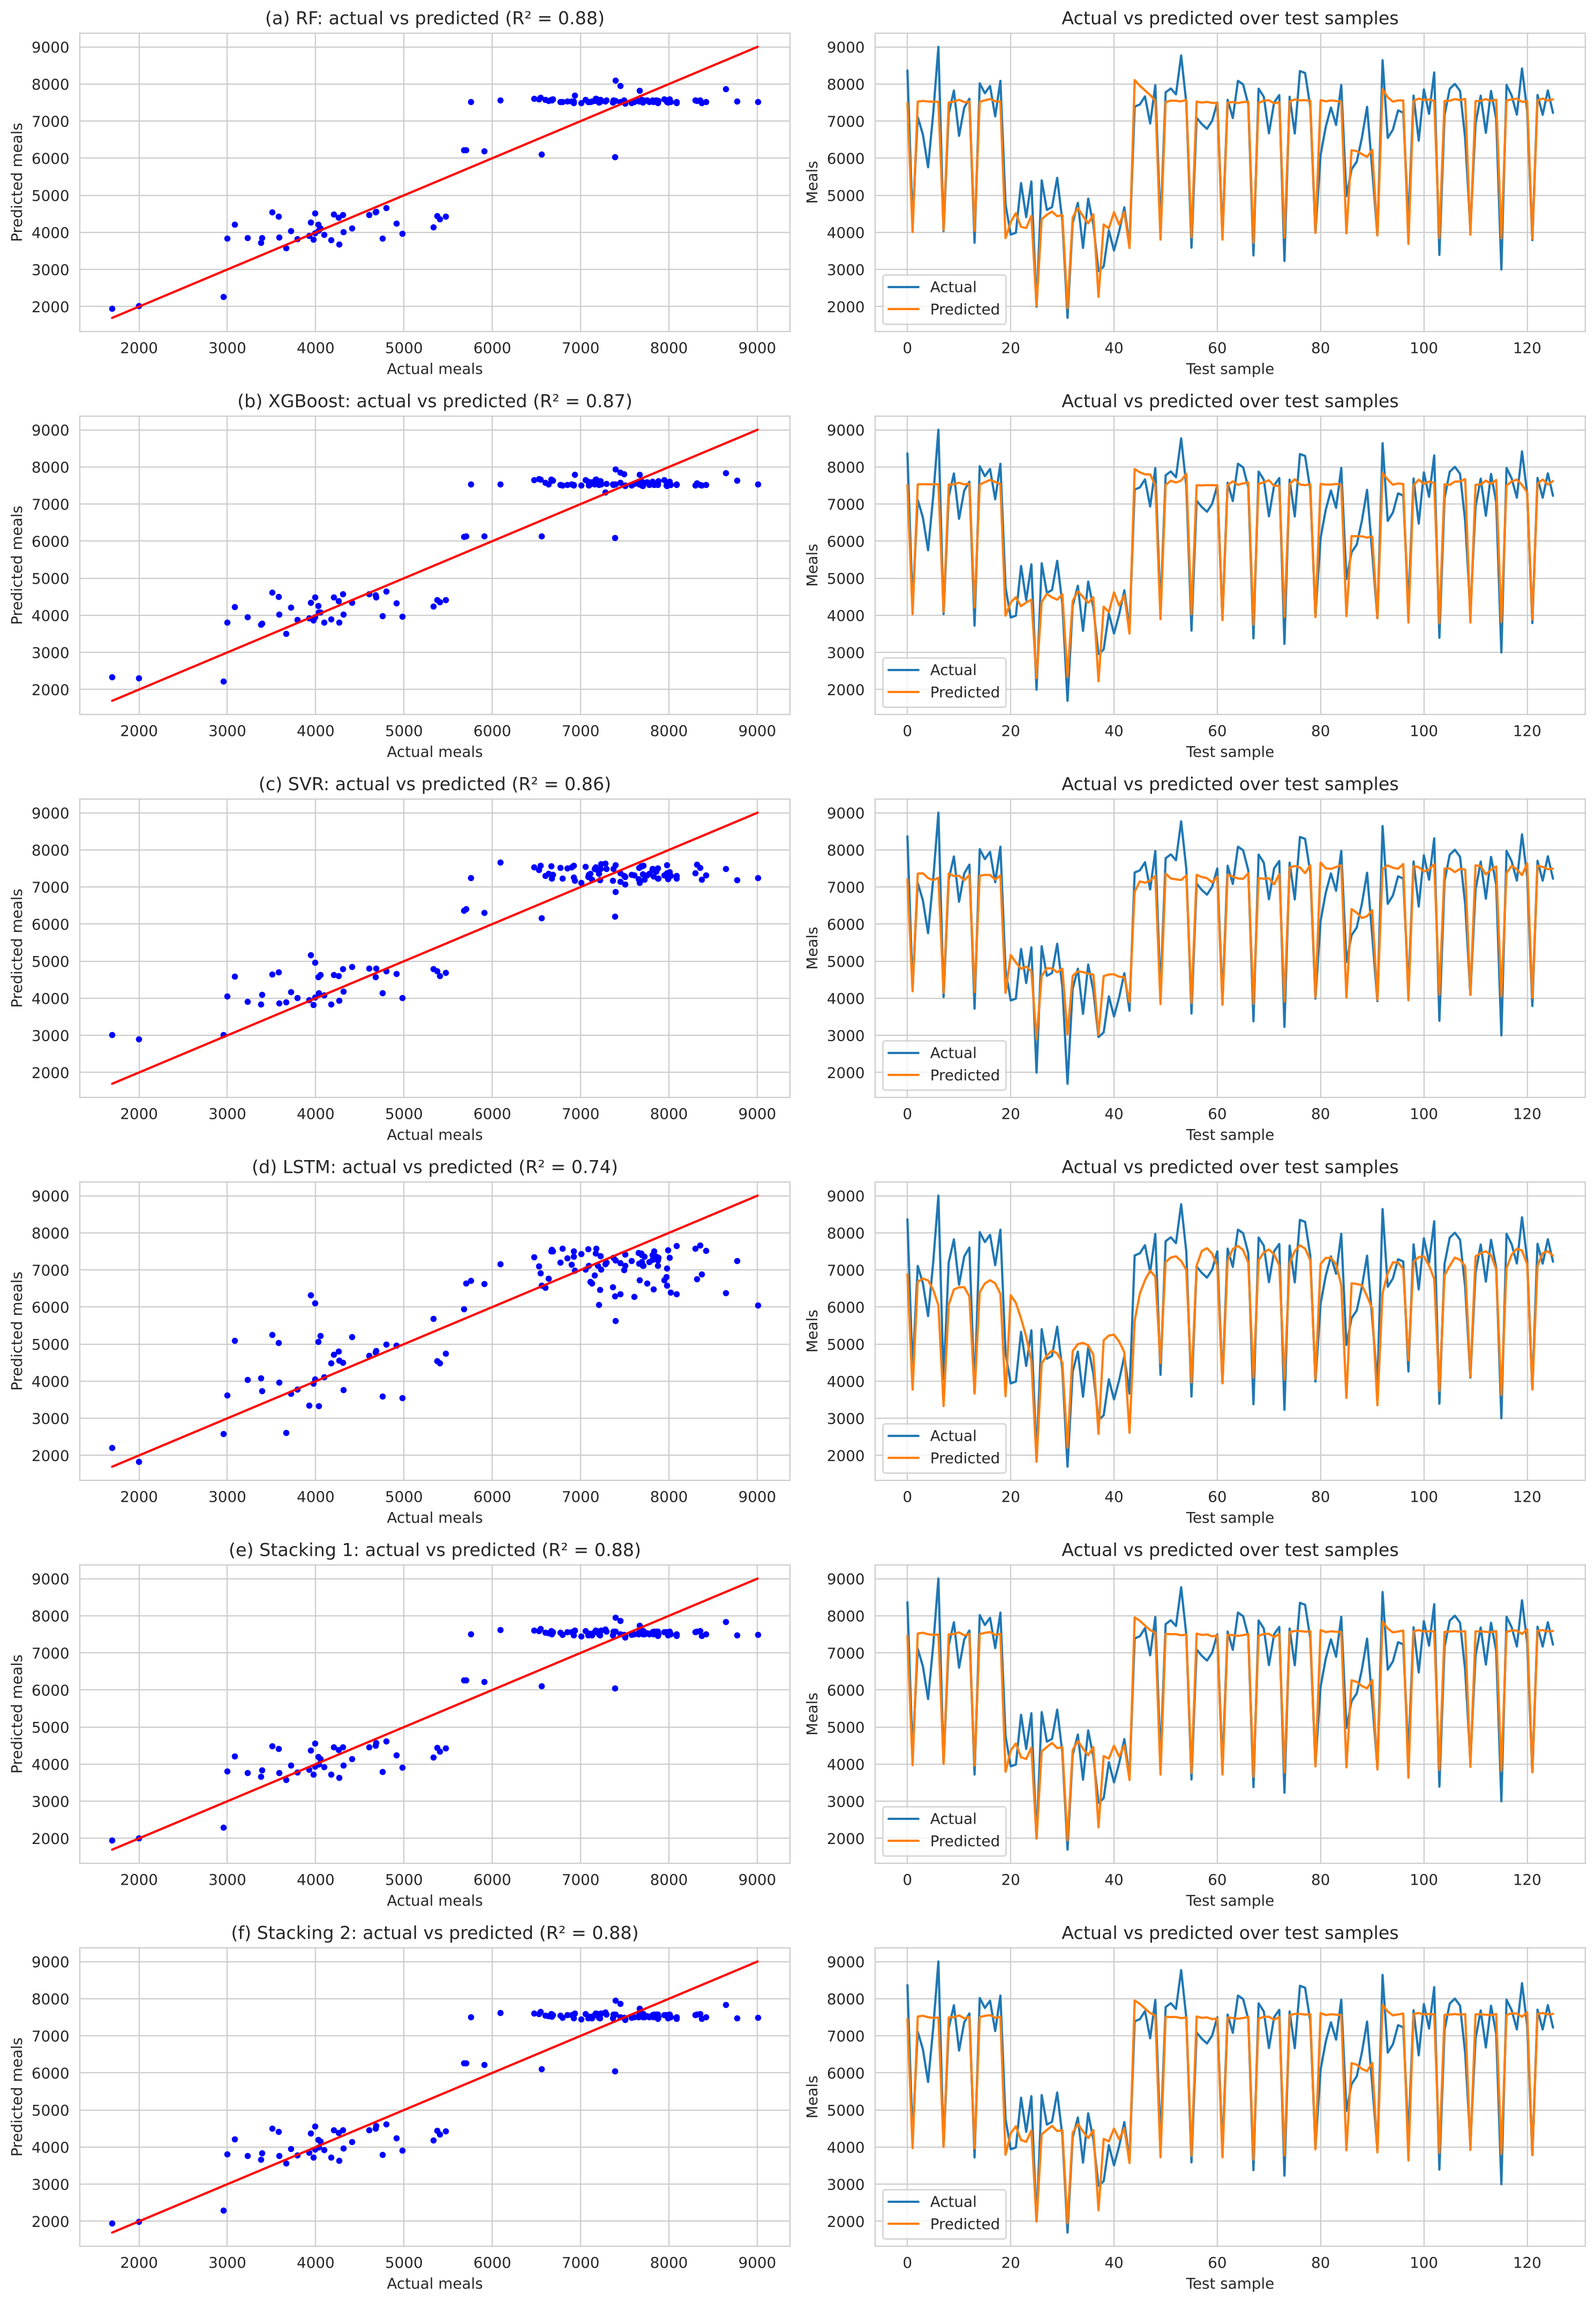

In [15]:
fig, axes = plt.subplots(len(preds), 2, figsize=(15, 3.6 * len(preds)))
for i, (name, p_) in enumerate(preds.items()):
    a = truth[name]; lims = [a.min(), a.max()]
    # Scatter of predicted vs actual with the identity line
    axes[i, 0].scatter(a, p_, s=10, c="blue"); axes[i, 0].plot(lims, lims, "r-")
    axes[i, 0].set(title=f"({'abcdef'[i]}) {name}: actual vs predicted (R² = {r2_score(a, p_):.2f})",
                   xlabel="Actual meals", ylabel="Predicted meals")
    # Actual and predicted series over the test samples
    axes[i, 1].plot(a, label="Actual"); axes[i, 1].plot(p_, label="Predicted")
    axes[i, 1].set(title="Actual vs predicted over test samples", xlabel="Test sample", ylabel="Meals"); axes[i, 1].legend()
plt.tight_layout(); plt.show()

### Accuracy vs training time
R² (higher is better) and training time for each model, with the value labelled on each bar.

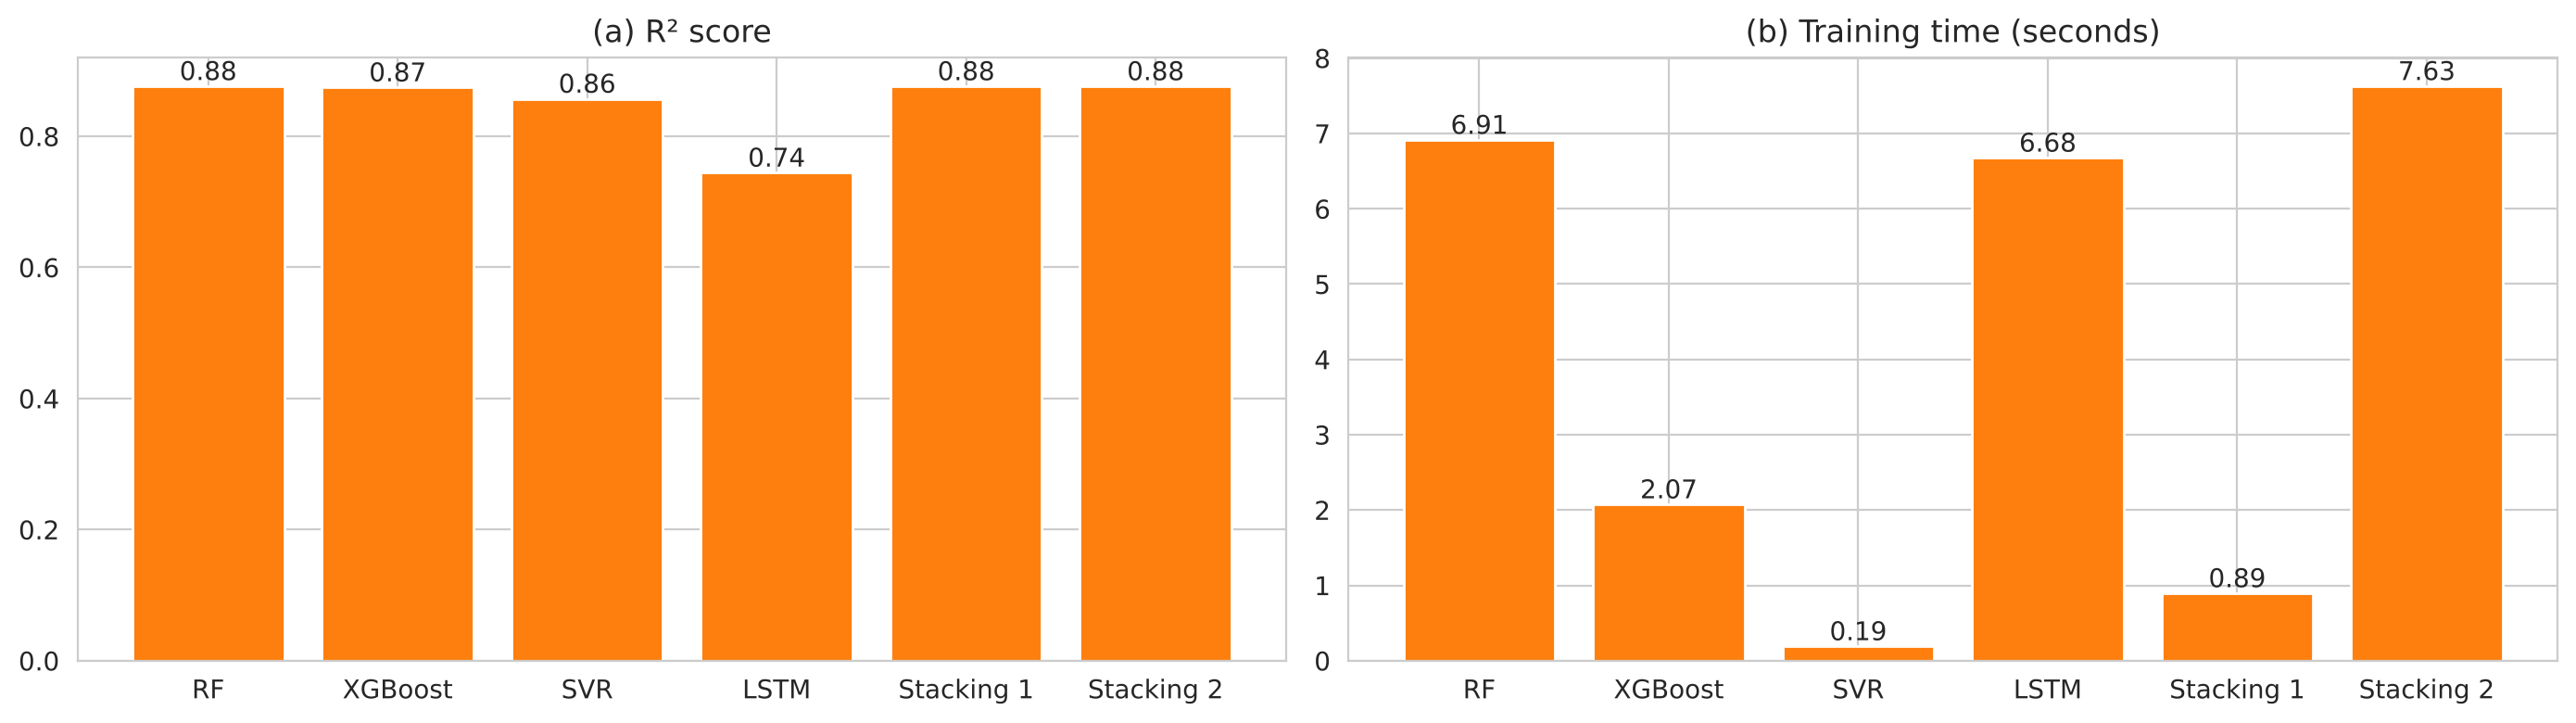

In [16]:
t = res.rename(index=lambda s: s.split(" (")[0])        # short model names for the x-axis
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, col, title in [(ax[0], "R2", "(a) R² score"), (ax[1], "Training time (s)", "(b) Training time (seconds)")]:
    a.bar(t.index, t[col], color="tab:orange"); a.set_title(title)
    for x, v in enumerate(t[col]): a.annotate(f"{v:.2f}", (x, v), ha="center", va="bottom")
plt.tight_layout(); plt.show()

## 11. Stacking training time vs accuracy
This section is new. Both stacks are trained again with the original way of choosing alpha: a 5-fold GridSearchCV around the whole stack, which retrains all base models for every alpha value. The base models, settings and folds are the same as in Sections 8 and 9, so the only difference is how alpha is chosen.

- Stacking time: time to train the stack, including choosing alpha (and, for Stacking 2, training its LSTM).
- Total time: stacking time plus the grid search and training of the base models the stack reuses (their training times in the results table).

Why the new method is faster: alpha only changes the Ridge step, and Ridge only sees the base models' out-of-fold predictions. The original grid search retrained every base model for each alpha value and fold (25 times plus a final fit), which gives the same base-model predictions every time. RidgeCV compares the same alpha values with the same MAE scoring directly on those predictions, so the base models are only trained once per fold.

alpha      MAE     RMSE  \
Stack      Meta-learner tuning                                                
Stacking 1 Original: GridSearchCV around the stack   0.01  485.241  608.126   
           New: RidgeCV meta-learner                 0.01  485.241  608.126   
Stacking 2 Original: GridSearchCV around the stack   0.01  485.228  608.061   
           New: RidgeCV meta-learner                 0.01  485.228  608.061   

                                                    SMAPE (%)     R2  \
Stack      Meta-learner tuning                                         
Stacking 1 Original: GridSearchCV around the stack      8.223  0.876   
           New: RidgeCV meta-learner                    8.223  0.876   
Stacking 2 Original: GridSearchCV around the stack      8.222  0.876   
           New: RidgeCV meta-learner                    8.222  0.876   

                                                    Stacking time (s)  \
Stack      Meta-learner tuning                                          
Stacking 1 Original: GridSearchCV around the stack             20.464   
           New: RidgeCV meta-learner                            0.894   
Stacking 2 Original: GridSearchCV around the stack             40.726   
           New: RidgeCV meta-learner                            7.627   

                                                    Total time (s)  
Stack      Meta-learner tuning                                      
Stacking 1 Original: GridSearchCV around the stack          29.642  
           New: RidgeCV meta-learner                        10.072  
Stacking 2 Original: GridSearchCV around the stack          49.903  
           New: RidgeCV meta-learner                        16.805

Stacking 1: stacking time 20.5s -> 0.9s (22.9x faster), total 29.6s -> 10.1s, MAE 485.2 -> 485.2 (+0.00%)
Stacking 2: stacking time 40.7s -> 7.6s (5.3x faster), total 49.9s -> 16.8s, MAE 485.2 -> 485.2 (-0.00%)


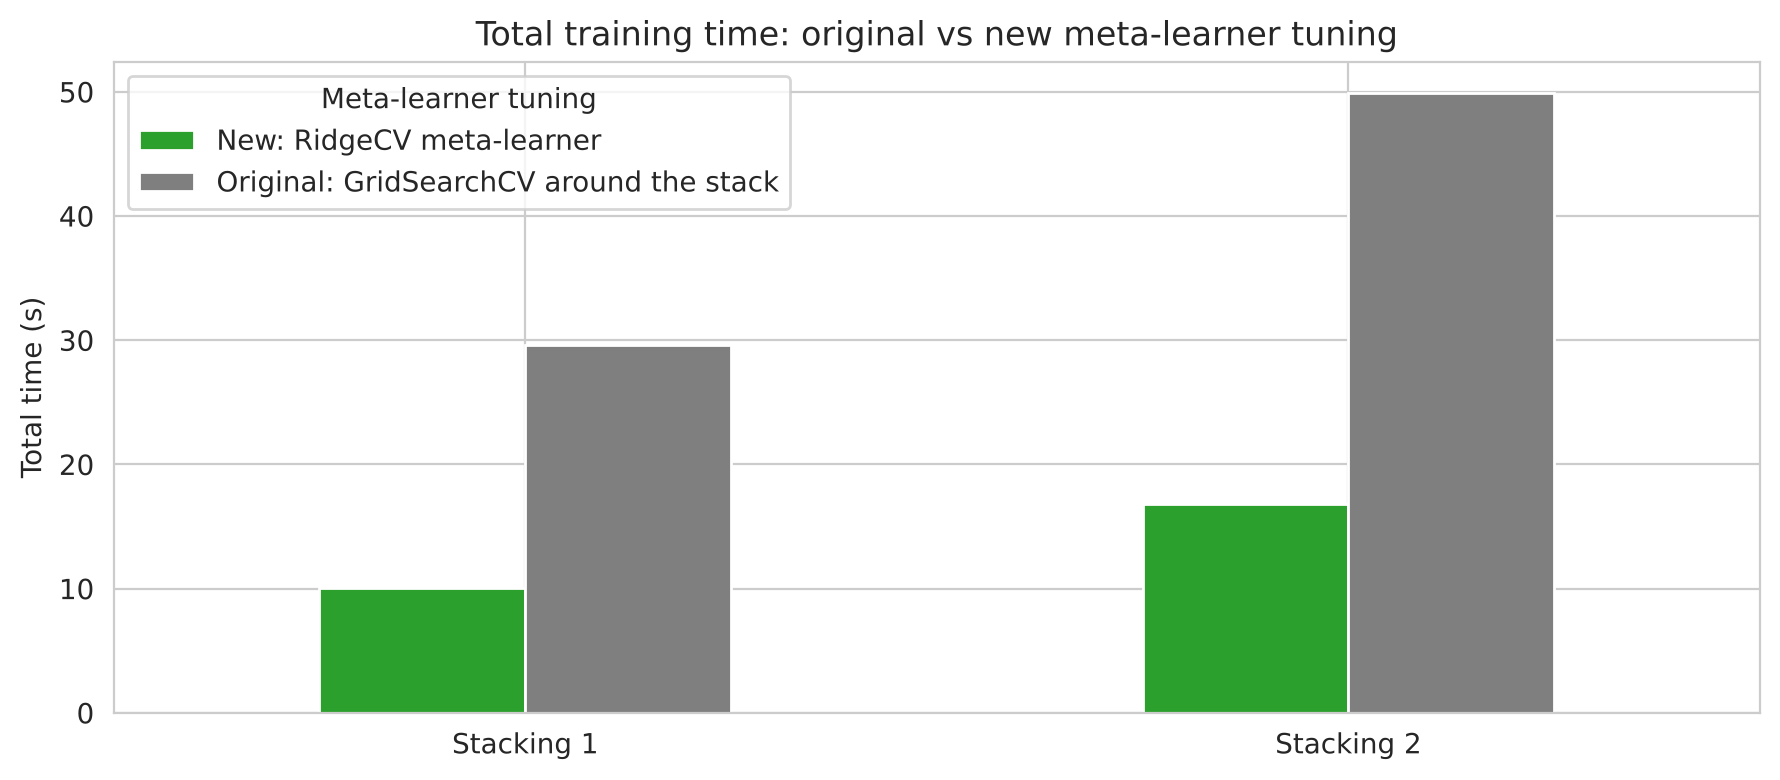

In [17]:
# CHANGED: new cell. Train both stacks with the original alpha tuning and compare with Sections 8 and 9
def original_tuning(estimators, X_fit):
    # Ridge meta-learner with alpha chosen by a GridSearchCV that retrains the whole stack for every alpha value
    stack = StackingRegressor(estimators=estimators, final_estimator=Ridge(), cv=CV_FOLDS, passthrough=False, n_jobs=-1)
    return GridSearchCV(stack, {"final_estimator__" + k: v for k, v in RIDGE_GRID.items()},
                        cv=CV_FOLDS, scoring=SCORING).fit(X_fit, y_tr)

base_secs = {r["Model"]: r["Training time (s)"] for r in results}                 # grid search and training time of each model
reuse = base_secs["RF"] + base_secs["XGBoost"] + base_secs["SVR"]                  # base-model time shared by both stacks

t0 = time.time()
o1 = original_tuning([("rf", best["RF"]), ("xgb", best["XGBoost"]), ("svr", best["SVR"])], X_tr)
o1_secs = time.time() - t0

t0 = time.time()
if STACK2_LSTM_MODE == "prefit":
    PREFIT_LSTM["stack2"] = LSTMRegressor(p).fit(W_all[idx_tr], y_tr)            # same single LSTM training as in Section 9
with parallel_backend("threading"):
    o2 = original_tuning([("rf", on_day(best["RF"])), ("xgb", on_day(best["XGBoost"])),
                          ("svr", on_day(best["SVR"])), ("lstm", lstm_base)], Z_tr)
    o2_pred = o2.predict(Z_te)
o2_secs = time.time() - t0

# One row per stack and tuning method: chosen alpha, accuracy and time
rows = []
for stack_name, tuning, pred, secs_, alpha in [
        ("Stacking 1", "Original: GridSearchCV around the stack", o1.predict(X_te), o1_secs, o1.best_params_["final_estimator__alpha"]),
        ("Stacking 1", "New: RidgeCV meta-learner", preds["Stacking 1"], base_secs["Stacking 1 (RF, XGBoost, SVR)"], s1.final_estimator_.alpha_),
        ("Stacking 2", "Original: GridSearchCV around the stack", o2_pred, o2_secs, o2.best_params_["final_estimator__alpha"]),
        ("Stacking 2", "New: RidgeCV meta-learner", preds["Stacking 2"], base_secs["Stacking 2 (RF, XGBoost, SVR, LSTM)"], s2.final_estimator_.alpha_)]:
    m = evaluate(stack_name, y_te, pred, secs_)
    rows.append({"Stack": stack_name, "Meta-learner tuning": tuning, "alpha": alpha,
                 "MAE": m["MAE"], "RMSE": m["RMSE"], "SMAPE (%)": m["SMAPE (%)"], "R2": m["R2"],
                 "Stacking time (s)": secs_, "Total time (s)": secs_ + reuse})
ro1 = pd.DataFrame(rows).set_index(["Stack", "Meta-learner tuning"])
display(ro1.round(3))

# Time saved and change in MAE for each stack
for s in ["Stacking 1", "Stacking 2"]:
    old, new = ro1.loc[s].iloc[0], ro1.loc[s].iloc[1]
    print(f"{s}: stacking time {old['Stacking time (s)']:.1f}s -> {new['Stacking time (s)']:.1f}s "
          f"({old['Stacking time (s)'] / new['Stacking time (s)']:.1f}x faster), total {old['Total time (s)']:.1f}s -> {new['Total time (s)']:.1f}s, "
          f"MAE {old['MAE']:.1f} -> {new['MAE']:.1f} ({(new['MAE'] / old['MAE'] - 1) * 100:+.2f}%)")

# Total training time of each stack with both tuning methods
ax = ro1["Total time (s)"].unstack().plot(kind="bar", figsize=(9, 4), rot=0, color=["tab:green", "tab:gray"])
ax.set(ylabel="Total time (s)", title="Total training time: original vs new meta-learner tuning", xlabel="")
plt.tight_layout(); plt.show()